In [1]:
# pip install numpy
# pip install pandas
# pip install matplotlib
# pip install seaborn
# pip install scipy

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [6]:
df = pd.read_excel("info/ENB2012_data.xlsx")
print(df.shape)
df.head()

(768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [ ]:
df.attrs["descriptions"] = {
    "X1": "Relative Compactness",
    "X2": "Surface Area",
    "X3": "Wall Area",
    "X4": "Roof Area",
    "X5": "Overall Height",
    "X6": "Orientation",
    "X7": "Glazing Area",
    "X8": "Glazing Area Distribution",
    "Y1": "Heating Load",
    "Y2": "Cooling Load",
}

df.attrs["descriptions"]["Y1"]

'Heating Load'

## Смотрим на датасет

In [8]:
miss = df.isnull().sum()
miss_pct = (miss / len(df) * 100).round(1)
pd.DataFrame({"пропусков": miss, "%": miss_pct}).query("`пропусков` > 0")

,пропусков,%


In [11]:
dup_count = df.duplicated().sum()
print(f"Полных дубликатов строк: {dup_count}")

Полных дубликатов строк: 0


## 3. Описательные статистики числовых признаков

In [12]:
num_cols = df.columns.to_list()
for i in range(2):
    del num_cols[-1]

print(num_cols)

stats_table = df[num_cols].describe().T
stats_table["median"] = df[num_cols].median()
stats_table["mode"] = df[num_cols].mode().iloc[0]
stats_table["IQR"] = stats_table["75%"] - stats_table["25%"]
stats_table["skew"] = df[num_cols].skew()
stats_table[["mean", "median", "mode", "std", "25%", "75%", "IQR", "skew"]].round(2)

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']


,mean,median,mode,std,25%,75%,IQR,skew
X1,0.76,0.75,0.62,0.11,0.68,0.83,0.15,0.50
X2,671.71,673.75,514.50,88.09,606.38,741.12,134.75,-0.13
X3,318.50,318.50,294.00,43.63,294.00,343.00,49.00,0.53
X4,176.60,183.75,220.50,45.17,140.88,220.50,79.62,-0.16
X5,5.25,5.25,3.50,1.75,3.50,7.00,3.50,0.00
X6,3.50,3.50,2.00,1.12,2.75,4.25,1.50,0.00
X7,0.23,0.25,0.10,0.13,0.10,0.40,0.30,-0.06
X8,2.81,3.00,1.00,1.55,1.75,4.00,2.25,-0.09


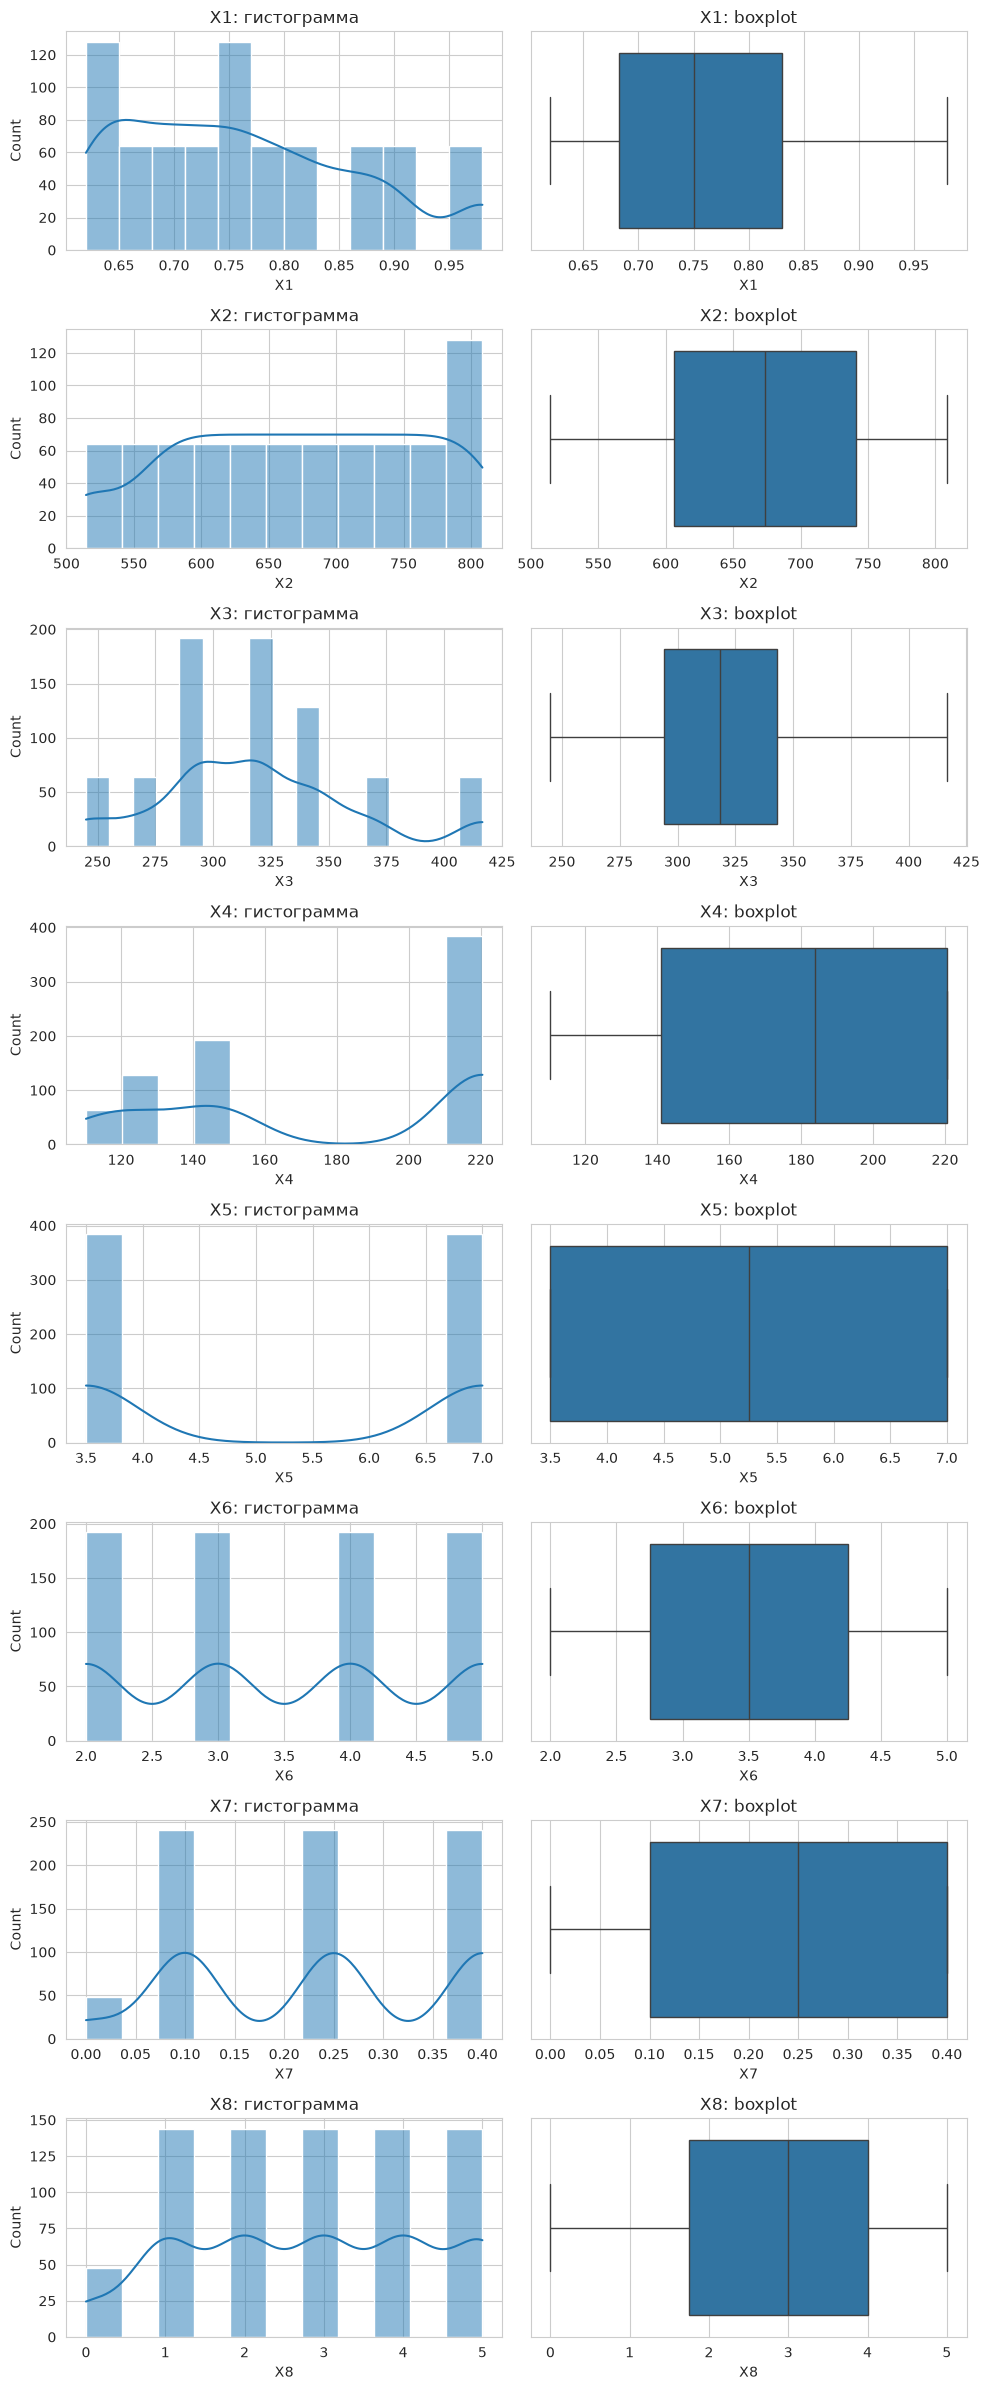

In [13]:
fig, axes = plt.subplots(len(num_cols), 2, figsize=(10, 3 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col}: гистограмма")
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col}: boxplot")
plt.tight_layout()
plt.show()

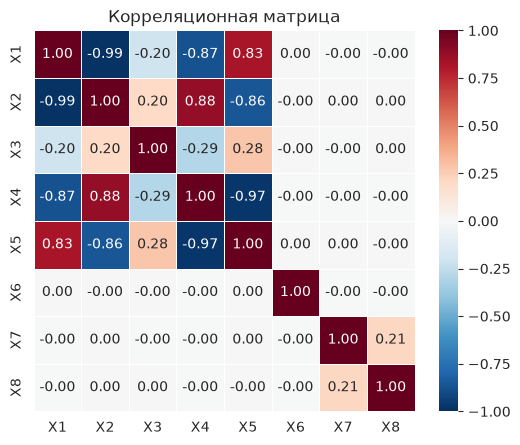

In [15]:
corr = df[num_cols].corr()

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()